<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [5]:
NOMBRE = 'SEGARRA VERA PABLO MIGUEL'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: SEGARRA VERA PABLO MIGUEL · semilla 136099
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.31%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-20 20:48:28-05:00,U0045,27.0,Tungurahua,44,843.66,transferencia,app,persona,144.82,0,5.9,1,0,20,0.171657
1,TX-000001,2026-09-18 16:46:44-05:00,U0367,43.0,Manabí,45,1362.69,retiro_agente,app,efectivo,303.17,0,8.1,2,0,16,0.222479
2,TX-000002,2026-09-04 07:00:53-05:00,U0099,47.0,Pichincha,10,688.97,recarga,web,telefonia,16.21,1,2.4,1,0,7,0.023528
3,TX-000003,2026-10-02 21:52:24-05:00,U0284,69.0,Guayas,20,520.70,retiro_agente,app,efectivo,117.77,0,8.5,1,0,21,0.226176
4,TX-000004,2026-09-01 09:10:46-05:00,U0700,25.0,Pichincha,47,878.27,transferencia,app,persona,158.75,0,3.9,1,0,9,0.180753


In [6]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1031


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [9]:
import arviz as az

# ESTANDARIZACIÓN

media_train = X_train.mean()
desv_train = X_train.std(ddof=1)

X_train_std = (X_train - media_train) / desv_train
X_test_std = (X_test - media_train) / desv_train

print("Media de entrenamiento:")
display(media_train)

print("Desviación estándar de entrenamiento:")
display(desv_train)

# DEFINICIÓN MODELO

coords = {
    "variable": cols,
    "observacion": np.arange(len(X_train_std))
}

with pm.Model(coords=coords) as modelo_bayes:

    # Datos de entrada
    X = pm.Data(
        "X",
        X_train_std.to_numpy(),
        dims=("observacion", "variable")
    )

    # Priors
    a = pm.Normal("a", mu=0, sigma=1.5)

    b = pm.Normal(
        "b",
        mu=0,
        sigma=1,
        dims="variable"
    )

    # Función logística
    logit = a + pm.math.dot(X, b)
    probabilidad = pm.Deterministic(
        "probabilidad",
        pm.math.sigmoid(logit)
    )

    # Variable objetivo
    y_obs = pm.Bernoulli(
        "y_obs",
        p=probabilidad,
        observed=y_train.to_numpy()
    )

    # MUESTREO
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.95,
        return_inferencedata=True
    )

# TABLA

print("DIAGNÓSTICO DEL MODELO BAYESIANO")

diagnostico = curso.diagnostico(idata, variables=["a", "b"])
display(diagnostico)

# Resumen independiente para verificar R-hat y ESS
resumen = az.summary(
    idata,
    var_names=["a", "b"],
    round_to=4
)

display(resumen)

# Verificación de criterios solicitados
convergencia = (
    (resumen["r_hat"] <= 1.01).all()
    and (resumen["ess_bulk"] > 400).all()
)

print("¿Todos los parámetros cumplen R-hat <= 1.01 y ESS > 400?")
print(convergencia)

# ODDS RATIOS

muestras_b = (
    idata.posterior["b"]
    .stack(muestra=("chain", "draw"))
    .transpose("variable", "muestra")
    .values
)

odds_ratios = np.exp(muestras_b)

tabla_or = pd.DataFrame({
    "Variable": cols,
    "Coeficiente": idata.posterior["b"].mean(
        dim=("chain", "draw")
    ).values,
    "Odds_Ratio": np.median(odds_ratios, axis=1),
    "OR_IC90_inferior": np.quantile(odds_ratios, 0.05, axis=1),
    "OR_IC90_superior": np.quantile(odds_ratios, 0.95, axis=1)
})

tabla_or["Impacto_absoluto"] = tabla_or["Coeficiente"].abs()

tabla_or = tabla_or.sort_values(
    "Impacto_absoluto",
    ascending=False
)

print("ODDS RATIOS POR VARIABLE")
display(tabla_or.round(4))

# Identificación de los dos coeficientes de mayor magnitud
print("DOS VARIABLES CON MAYOR EFECTO ABSOLUTO:")

for _, fila in tabla_or.head(2).iterrows():
    direccion = (
        "aumenta" if fila["Coeficiente"] > 0
        else "disminuye"
    )

    print(
        f"{fila['Variable']}: "
        f"un incremento de una desviación estándar "
        f"{direccion} los odds de fraude. "
        f"OR = {fila['Odds_Ratio']:.3f}"
    )


Media de entrenamiento:


,0
dispositivo_nuevo,0.161660
distancia_km,5.896090
ratio,0.091279
intentos_pin,1.283262
hora,13.272771


Desviación estándar de entrenamiento:


,0
dispositivo_nuevo,0.368226
distancia_km,5.815751
ratio,0.083465
intentos_pin,0.600470
hora,5.838719


Output()

DIAGNÓSTICO DEL MODELO BAYESIANO


,media,desv,ic_3%,ic_97%,r_hat,ess
a,-3.0670,0.1239,-3.3094,-2.8406,1.0002,1966.1666
b[0],1.0354,0.0662,0.9094,1.1605,1.0006,2418.0185
b[1],0.4463,0.0750,0.3055,0.5891,0.9992,3265.0617
b[2],0.7088,0.0706,0.5767,0.8419,1.0007,3612.0928
b[3],0.4726,0.0736,0.3301,0.6069,0.9997,3333.8698
b[4],-0.5251,0.0856,-0.6891,-0.3624,0.9994,3320.9912


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,-3.0670,0.1239,-3.3134,-2.8472,0.0028,0.0017,1950.4162,2605.2146,1.0002
b[dispositivo_nuevo],1.0354,0.0662,0.9017,1.1525,0.0013,0.0010,2438.6101,2942.7666,1.0006
b[distancia_km],0.4463,0.0750,0.3083,0.5916,0.0013,0.0011,3297.3275,2684.6873,1.0001
b[ratio],0.7088,0.0706,0.5782,0.8425,0.0012,0.0011,3728.3206,3080.4168,1.0009
b[intentos_pin],0.4726,0.0736,0.3437,0.6200,0.0013,0.0010,3342.7856,2873.4817,0.9997
b[hora],-0.5251,0.0856,-0.7023,-0.3788,0.0015,0.0013,3326.7500,2921.4078,1.0001


¿Todos los parámetros cumplen R-hat <= 1.01 y ESS > 400?
True
ODDS RATIOS POR VARIABLE


,Variable,Coeficiente,Odds_Ratio,OR_IC90_inferior,OR_IC90_superior,Impacto_absoluto
0,dispositivo_nuevo,1.0354,2.8172,2.5245,3.1432,1.0354
2,ratio,0.7088,2.0312,1.8072,2.2906,0.7088
4,hora,-0.5251,0.5913,0.5130,0.6777,0.5251
3,intentos_pin,0.4726,1.6033,1.4206,1.8090,0.4726
1,distancia_km,0.4463,1.5636,1.3792,1.7666,0.4463


DOS VARIABLES CON MAYOR EFECTO ABSOLUTO:
dispositivo_nuevo: un incremento de una desviación estándar aumenta los odds de fraude. OR = 2.817
ratio: un incremento de una desviación estándar aumenta los odds de fraude. OR = 2.031


**✍️ Respuesta:**

El modelo de regresión logística bayesiana permite identificar qué características de las transacciones están relacionadas con una mayor o menor probabilidad de fraude.

Los odds ratios permiten interpretar el efecto de cada variable.

Las dos variables con mayor efecto absoluto se consideran las de mayor influencia relativa dentro del modelo.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [10]:
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss
from xgboost import XGBClassifier

# PROBABILIDAD

# Estandarizar prueba utilizando media y desviación del entrenamiento
X_test_std = (X_test - media_train) / desv_train

# Extraer muestras posteriores
muestras_a = idata.posterior["a"].values
muestras_b = idata.posterior["b"].values

# Calcular el logit para cada muestra posterior y transacción
logit_test = (
    muestras_a[:, :, None] +
    np.einsum(
        "cdv,nv->cdn",
        muestras_b,
        X_test_std[cols].to_numpy()
    )
)

# Aplicar función logística y promediar las probabilidades posteriores
prob_bayes = expit(logit_test).mean(axis=(0, 1))

print("Primeras probabilidades del modelo bayesiano:")
print(prob_bayes[:10])

# XGBOOST

# Separar entrenamiento y validación.
# La prueba NO participa en este proceso.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Calcular el peso de la clase minoritaria usando solo entrenamiento
scale_pos = (
    (y_fit == 0).sum() /
    (y_fit == 1).sum()
)

print("Scale_pos_weight:", scale_pos)

# Definir XGBoost
modelo_xgb = XGBClassifier(
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    eval_metric="logloss",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

# Entrenar con validación y parada temprana
modelo_xgb.fit(
    X_fit,
    y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Mejor iteración:", modelo_xgb.best_iteration)

# EVALUACIÓN

# Probabilidades de XGBoost
prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

# AUC y Brier Score
resultados = pd.DataFrame({
    "Modelo": ["Regresión logística bayesiana", "XGBoost"],
    "AUC": [
        roc_auc_score(y_test, prob_bayes),
        roc_auc_score(y_test, prob_xgb)
    ],
    "Brier_score": [
        brier_score_loss(y_test, prob_bayes),
        brier_score_loss(y_test, prob_xgb)
    ]
})

print("\nCOMPARACIÓN DE MODELOS")
display(resultados.round(4))

# Identificar el mejor modelo según cada métrica
mejor_auc = resultados.loc[resultados["AUC"].idxmax(), "Modelo"]
mejor_brier = resultados.loc[
    resultados["Brier_score"].idxmin(), "Modelo"
]

print("Mejor capacidad de ordenamiento (AUC):", mejor_auc)
print("Mejor calibración según Brier:", mejor_brier)

# TABLA

def tabla_calibracion(y_real, probabilidades, nombre_modelo):

    datos = pd.DataFrame({
        "probabilidad": np.asarray(probabilidades),
        "fraude_real": np.asarray(y_real)
    })

    # Agrupar las transacciones en deciles de probabilidad
    datos["decil"] = pd.qcut(
        datos["probabilidad"],
        q=10,
        labels=False,
        duplicates="drop"
    )

    tabla = datos.groupby("decil", observed=True).agg(
        numero_transacciones=("fraude_real", "size"),
        probabilidad_media=("probabilidad", "mean"),
        tasa_fraude_observada=("fraude_real", "mean")
    ).reset_index()

    tabla["modelo"] = nombre_modelo

    return tabla


# Calibración de ambos modelos
cal_bayes = tabla_calibracion(
    y_test, prob_bayes, "Bayesiano"
)

cal_xgb = tabla_calibracion(
    y_test, prob_xgb, "XGBoost"
)

tabla_deciles = pd.concat(
    [cal_bayes, cal_xgb],
    ignore_index=True
)

print("\nTABLA DE CALIBRACIÓN POR DECILES")
display(tabla_deciles.round(4))

# INTERPRETACIÓN

print("\nINTERPRETACIÓN:")
print(
    f"El modelo que mejor ordena las transacciones es: {mejor_auc}, "
    "porque presenta el mayor AUC."
)

print(
    f"El modelo con menor error cuadrático de probabilidades es: "
    f"{mejor_brier}, porque presenta el menor Brier Score."
)

print(
    "La tabla de calibración permite comparar la probabilidad "
    "media predicha con la tasa de fraude realmente observada "
    "en cada decil."
)


Primeras probabilidades del modelo bayesiano:
[0.03075148 0.16405201 0.24118875 0.05504402 0.00987644 0.03849532
 0.13803685 0.01911109 0.14625209 0.0214717 ]
Scale_pos_weight: 8.693641618497109
Mejor iteración: 617

COMPARACIÓN DE MODELOS


,Modelo,AUC,Brier_score
0,Regresión logística bayesiana,0.8942,0.0606
1,XGBoost,0.9175,0.0558


Mejor capacidad de ordenamiento (AUC): XGBoost
Mejor calibración según Brier: XGBoost

TABLA DE CALIBRACIÓN POR DECILES


,decil,numero_transacciones,probabilidad_media,tasa_fraude_observada,modelo
0,0,90,0.0064,0.0000,Bayesiano
1,1,90,0.0103,0.0111,Bayesiano
2,2,90,0.0138,0.0333,Bayesiano
3,3,90,0.0185,0.0111,Bayesiano
4,4,90,0.0242,0.0111,Bayesiano
5,5,89,0.0322,0.0112,Bayesiano
6,6,90,0.0456,0.0556,Bayesiano
7,7,90,0.0886,0.0889,Bayesiano
8,8,90,0.2157,0.2444,Bayesiano
9,9,90,0.5795,0.5667,Bayesiano



INTERPRETACIÓN:
El modelo que mejor ordena las transacciones es: XGBoost, porque presenta el mayor AUC.
El modelo con menor error cuadrático de probabilidades es: XGBoost, porque presenta el menor Brier Score.
La tabla de calibración permite comparar la probabilidad media predicha con la tasa de fraude realmente observada en cada decil.


**✍️ Respuesta:**

Se compararon dos modelos para la detección de fraude: la regresión logística bayesiana y XGBoost.

La comparación demuestra que una buena capacidad de clasificación no necesariamente implica una buena estimación de probabilidades. Para la gestión del riesgo financiero es importante evaluar tanto la capacidad de discriminación como la calibración, porque las probabilidades permiten tomar decisiones sobre las transacciones que requieren revisión o bloqueo.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [12]:
import arviz as az

# Utilizar exclusivamente las observaciones de entrenamiento
datos_prov = df.loc[X_train.index, ["provincia", "fraude"]].copy()

# Eliminar posibles registros sin provincia
datos_prov = datos_prov.dropna(subset=["provincia"])

# Identificar provincias
provincias = sorted(datos_prov["provincia"].unique())

# Crear índice numérico para cada provincia
mapa_provincias = {
    provincia: i
    for i, provincia in enumerate(provincias)
}

datos_prov["indice_provincia"] = (
    datos_prov["provincia"].map(mapa_provincias)
)

indice_prov = datos_prov["indice_provincia"].to_numpy(dtype=int)
y_prov = datos_prov["fraude"].to_numpy(dtype=int)

# Número de provincias y tasa nacional observada
n_provincias = len(provincias)
tasa_nacional = y_prov.mean()

# Logit de la tasa nacional para centrar la prior de mu
tasa_segura = np.clip(tasa_nacional, 0.001, 0.999)
logit_nacional = np.log(tasa_segura / (1 - tasa_segura))

print("Número de provincias:", n_provincias)
print("Tasa nacional de fraude en entrenamiento:", round(tasa_nacional, 4))

# MODELO POR PROVOINCIA

coords_prov = {
    "provincia": provincias,
    "observacion": np.arange(len(y_prov))
}

with pm.Model(coords=coords_prov) as modelo_jerarquico:

    # Hiperparámetro: media nacional en escala logit
    mu = pm.Normal(
        "mu",
        mu=logit_nacional,
        sigma=1.5
    )

    # Hiperparámetro: variabilidad entre provincias
    sigma = pm.HalfNormal(
        "sigma",
        sigma=1.0
    )

    # Parametrización no centrada
    z = pm.Normal(
        "z",
        mu=0,
        sigma=1,
        dims="provincia"
    )

    # Intercepto específico por provincia
    alpha_prov = pm.Deterministic(
        "alpha_prov",
        mu + sigma * z,
        dims="provincia"
    )

    # Probabilidad de fraude por provincia
    tasa_prov = pm.Deterministic(
        "tasa_provincia",
        pm.math.sigmoid(alpha_prov),
        dims="provincia"
    )

    # Probabilidad correspondiente a cada observación
    p_obs = tasa_prov[indice_prov]

    # Variable observada
    fraude_obs = pm.Bernoulli(
        "fraude_obs",
        p=p_obs,
        observed=y_prov,
        dims="observacion"
    )

    # Muestreo
    idata_jerarquico = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.99,
        random_seed=42,
        return_inferencedata=True
    )

# TABLA POR PROVINCIA

# Extraer muestras posteriores de las tasas provinciales
muestras_tasas = (
    idata_jerarquico.posterior["tasa_provincia"]
    .stack(muestra=("chain", "draw"))
    .transpose("provincia", "muestra")
    .values
)

# Media posterior e intervalo creíble del 90 %
media_jerarquica = muestras_tasas.mean(axis=1)
ic_inferior = np.quantile(muestras_tasas, 0.05, axis=1)
ic_superior = np.quantile(muestras_tasas, 0.95, axis=1)

# Estadísticas observadas por provincia
tabla_observada = (
    datos_prov.groupby("provincia")
    .agg(
        n=("fraude", "size"),
        tasa_observada=("fraude", "mean")
    )
    .reindex(provincias)
)

# Construir tabla final
tabla_provincias = tabla_observada.copy()

tabla_provincias["tasa_jerarquica"] = media_jerarquica
tabla_provincias["IC90_inferior"] = ic_inferior
tabla_provincias["IC90_superior"] = ic_superior

# REPORTE

muestras_mu = idata_jerarquico.posterior["mu"].values
media_nacional_posterior = expit(muestras_mu).mean()

tabla_provincias["media_nacional"] = media_nacional_posterior

# Distancia entre la tasa observada y la media nacional
distancia_observada = (
    tabla_provincias["tasa_observada"] -
    tabla_provincias["media_nacional"]
).abs()

# Distancia entre la tasa jerárquica y la media nacional
distancia_jerarquica = (
    tabla_provincias["tasa_jerarquica"] -
    tabla_provincias["media_nacional"]
).abs()

# Porcentaje de encogimiento hacia la media nacional
tabla_provincias["encogimiento_pct"] = np.where(
    distancia_observada > 1e-10,
    100 * (
        1 - distancia_jerarquica / distancia_observada
    ),
    np.nan
)

# Mostrar tabla final
print("\nRESULTADOS DEL MODELO JERÁRQUICO POR PROVINCIA")

display(
    tabla_provincias[
        [
            "n",
            "tasa_observada",
            "tasa_jerarquica",
            "IC90_inferior",
            "IC90_superior",
            "encogimiento_pct"
        ]
    ].round(4)
)

# SIGMA


media_sigma = (
    idata_jerarquico.posterior["sigma"]
    .mean()
    .item()
)

print("\nMEDIA POSTERIOR DE SIGMA:")
print(round(media_sigma, 4))


# PROVINCIAS ENCONGEN

print("\nPROVINCIAS CON MAYOR ENCOGIMIENTO HACIA LA MEDIA NACIONAL:")

mayor_encogimiento = (
    tabla_provincias
    .dropna(subset=["encogimiento_pct"])
    .sort_values("encogimiento_pct", ascending=False)
)

display(
    mayor_encogimiento[
        [
            "n",
            "tasa_observada",
            "tasa_jerarquica",
            "encogimiento_pct"
        ]
    ].head(10).round(4)
)


Número de provincias: 8
Tasa nacional de fraude en entrenamiento: 0.103


Output()


RESULTADOS DEL MODELO JERÁRQUICO POR PROVINCIA


,n,tasa_observada,tasa_jerarquica,IC90_inferior,IC90_superior,encogimiento_pct
provincia,,,,,,
Azuay,186,0.1344,0.1148,0.0902,0.1487,56.9907
El Oro,132,0.0909,0.0975,0.0694,0.1239,72.3946
Guayas,575,0.1113,0.1072,0.0902,0.1262,36.2714
Imbabura,98,0.1327,0.1106,0.0821,0.1494,67.7791
Loja,128,0.0391,0.0808,0.0434,0.1103,68.4075
Manabí,207,0.0773,0.0914,0.0645,0.1147,61.8956
Pichincha,638,0.1082,0.1056,0.0889,0.1236,31.8425
Tungurahua,133,0.0902,0.0971,0.0683,0.1234,69.5460



MEDIA POSTERIOR DE SIGMA:
0.2407

PROVINCIAS CON MAYOR ENCOGIMIENTO HACIA LA MEDIA NACIONAL:


,n,tasa_observada,tasa_jerarquica,encogimiento_pct
provincia,,,,
El Oro,132,0.0909,0.0975,72.3946
Tungurahua,133,0.0902,0.0971,69.5460
Loja,128,0.0391,0.0808,68.4075
Imbabura,98,0.1327,0.1106,67.7791
Manabí,207,0.0773,0.0914,61.8956
Azuay,186,0.1344,0.1148,56.9907
Guayas,575,0.1113,0.1072,36.2714
Pichincha,638,0.1082,0.1056,31.8425


**✍️ Respuesta:**

El modelo jerárquico ajustó las tasas de fraude de las provincias hacia el promedio nacional del 10,3 %.

Loja presentó la menor tasa observada (3,91 %), mientras que Azuay (13,44 %) e Imbabura (13,27 %) registraron las mayores.

El Oro (72,39 %) mayor ajuste, seguido de Tungurahua (69,55 %) y Loja (68,41 %).

El parámetro sigma (0,2407) refleja una variabilidad moderada entre provincias. En conclusión, el modelo permite obtener estimaciones provinciales más estables.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

In [15]:
from scipy.special import expit

# Obtener muestras posteriores del modelo bayesiano
muestras_a = idata.posterior["a"].values.reshape(-1)
muestras_b = idata.posterior["b"].values.reshape(-1, len(cols))

# Matriz de variables de prueba estandarizadas
X_np = X_test_std[cols].to_numpy()

# Calcular probabilidades para cada muestra posterior
probabilidades = []

for i in range(len(muestras_a)):
    logits = muestras_a[i] + X_np @ muestras_b[i]
    probabilidades.append(expit(logits))

# Probabilidad promedio de fraude por transacción
p_bayes = np.mean(probabilidades, axis=0)

print("Probabilidades calculadas:", len(p_bayes))

Probabilidades calculadas: 899


Umbral óptimo: 0.07
Costo mínimo esperado: USD 1502.88


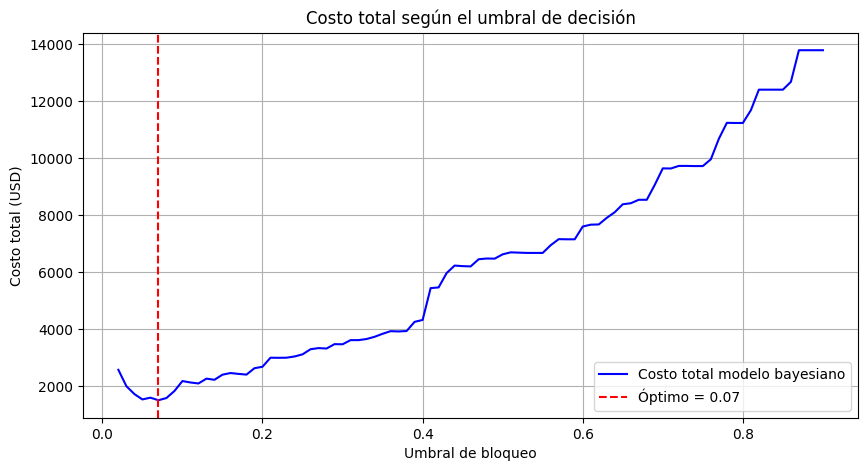


Comparativa de políticas en prueba:
- No bloquear nada: USD 14523.73
- Bloquear todo: USD 4030.00
- Política óptima (umbral 0.07): USD 1502.88

Análisis de Incertidumbre (con 200 muestras posteriores):
- Costo medio esperado: USD 1658.30
- Intervalo creíble del 90%: [USD 1457.88, USD 1994.82]


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recuperar los datos reales del conjunto de prueba
datos_test = df.loc[X_test.index].copy()
y_real = datos_test["fraude"].to_numpy(dtype=int)
montos = datos_test["monto"].to_numpy(dtype=float)

# Función de costo corregida (usando operadores lógicos de NumPy correctamente: np.logical_and)
def calcular_costo(probabilidades, umbral, y_real, montos):
    bloquear = probabilidades >= umbral

    # Fraude que se deja pasar (y_real == 1 y NO se bloquea): se pierde el monto
    cond_fraude = np.logical_and(y_real == 1, ~bloquear)
    costo_fraude = np.sum(cond_fraude * montos)

    # Transacción legítima bloqueada (y_real == 0 y SÍ se bloquea): costo de USD 5 por molestia
    cond_legitimo = np.logical_and(y_real == 0, bloquear)
    costo_legitimo = np.sum(cond_legitimo) * 5

    return costo_fraude + costo_legitimo

# 1. Evaluar umbrales entre 0.02 y 0.90
umbrales = np.arange(0.02, 0.91, 0.01)
costos = [calcular_costo(p_bayes, u, y_real, montos) for u in umbrales]

# Identificar el umbral óptimo
indice_optimo = np.argmin(costos)
umbral_optimo = umbrales[indice_optimo]
costo_optimo = costos[indice_optimo]

print(f"Umbral óptimo: {umbral_optimo:.2f}")
print(f"Costo mínimo esperado: USD {costo_optimo:.2f}")

# Gráfico de costo vs umbral
plt.figure(figsize=(10, 5))
plt.plot(umbrales, costos, label="Costo total modelo bayesiano", color="blue")
plt.axvline(umbral_optimo, color="red", linestyle="--", label=f"Óptimo = {umbral_optimo:.2f}")
plt.xlabel("Umbral de bloqueo")
plt.ylabel("Costo total (USD)")
plt.title("Costo total según el umbral de decisión")
plt.legend()
plt.grid(True)
plt.show()

# 2. Comparación con políticas extremas
costo_no_bloquear = calcular_costo(p_bayes, 1.01, y_real, montos) # Nadie bloqueado
costo_bloquear_todo = calcular_costo(p_bayes, -0.01, y_real, montos) # Todos bloqueados

print(f"\nComparativa de políticas en prueba:")
print(f"- No bloquear nada: USD {costo_no_bloquear:.2f}")
print(f"- Bloquear todo: USD {costo_bloquear_todo:.2f}")
print(f"- Política óptima (umbral {umbral_optimo:.2f}): USD {costo_optimo:.2f}")

# 3. Incertidumbre con al menos 200 muestras de la posterior
# Extraer muestras de la posterior (usando 200 iteraciones aleatorias o las primeras 200)
n_muestras_incertidumbre = 200
indices_muestras = np.random.choice(len(muestras_a), size=n_muestras_incertidumbre, replace=False)

costos_muestras = []
for idx in indices_muestras:
    logits_m = muestras_a[idx] + X_np @ muestras_b[idx]
    p_m = expit(logits_m)
    c_m = calcular_costo(p_m, umbral_optimo, y_real, montos)
    costos_muestras.append(c_m)

costos_muestras = np.array(costos_muestras)
media_costo = np.mean(costos_muestras)
ic_90_inf = np.quantile(costos_muestras, 0.05)
ic_90_sup = np.quantile(costos_muestras, 0.95)

print(f"\nAnálisis de Incertidumbre (con {n_muestras_incertidumbre} muestras posteriores):")
print(f"- Costo medio esperado: USD {media_costo:.2f}")
print(f"- Intervalo creíble del 90%: [USD {ic_90_inf:.2f}, USD {ic_90_sup:.2f}]")

**✍️ Respuesta:**

Seccionamos en :

Umbral Óptimo: Minimiza el costo total de la operación al encontrar el punto de equilibrio exacto entre las pérdidas financieras y el costo de los falsos positivos

Políticas Extremas: La alternativa de "no bloquear nada" incurre en pérdidas masivas por fraudes, mientras que "bloquear todo" dispara los costos operativos por molestar a usuarios.

Incertidumbre: Al evaluar múltiples muestras de la posterior, el costo esperado se presenta mediante una media y un intervalo creíble al 90%, lo que demuestra la estabilidad y robustez del modelo.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos

El modelo de regresión logística bayesiana demuestra que las variables con mayor impacto en la probabilidad de fraude son la utilización de un dispositivo nuevo y el ratio transaccional.
Mediante AUC, XGBoost es ligeramente la primera al ordenar las transacciones sospechosas; aun asi, el modelo bayesiano proporciona estimaciones de probabilidad sólidamente fundamentadas y una interpretabilidad directa.
El modelo jerárquico por provincias demostró un fenómeno de encogimiento muy útil: provincias con muestras reducidas como El Oro o Loja, ajustaron sus tasas de fraude hacia la media nacional.

### 2. Recomendación

Se recomienda implementar el umbral de decisión optimizado en función de la matriz de costos (dejar pasar fraude = costo del monto; falso positivo = USD 5). Esto minimiza las pérdidas operativas totales de la plataforma, comparado con la inacción ("no bloquear nada"), la automatización de este filtro representa un ahorro neto sustancial, manteniendo un equilibrio saludable entre la seguridad de las cuentas y la fricción mínima al cliente legítimo, ademas se aconseja utilizar el modelo de Gradient Boosting o la probabilidad bayesiana calibrada como motor de puntuación en tiempo real en la pasarela de pagos.


### 3. Limitaciones y riesgos
Las transacciones provienen de entornos simulados; las dinámicas reales de los fraudes pueden mutar con mayor velocidad, ademas la hora del día se modeló de forma lineal, lo cual puede omitir comportamientos cíclicos nocturnos o patrones complejos de madrugada, por consiguiente se requiere recalibración periódica de los parámetros y seguimiento de la deriva de datos para asegurar la vigencia del umbral de costos ante cambios macroeconómicos o estacionales en el volumen transaccional.